In [96]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

In [97]:
columns = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]

df = pd.read_csv(
    'adult.data',
    names=columns,
    sep=r',\s*',
    engine='python',
    na_values='?'
)


df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [98]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [99]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


(array([3.0913e+04, 8.7800e+02, 1.5700e+02, 3.6000e+02, 3.8000e+01,
        4.9000e+01, 5.0000e+00, 0.0000e+00, 2.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 1.5900e+02]),
 array([    0.  ,  4999.95,  9999.9 , 14999.85, 19999.8 , 24999.75,
        29999.7 , 34999.65, 39999.6 , 44999.55, 49999.5 , 54999.45,
        59999.4 , 64999.35, 69999.3 , 74999.25, 79999.2 , 84999.15,
        89999.1 , 94999.05, 99999.  ]),
 <BarContainer object of 20 artists>)

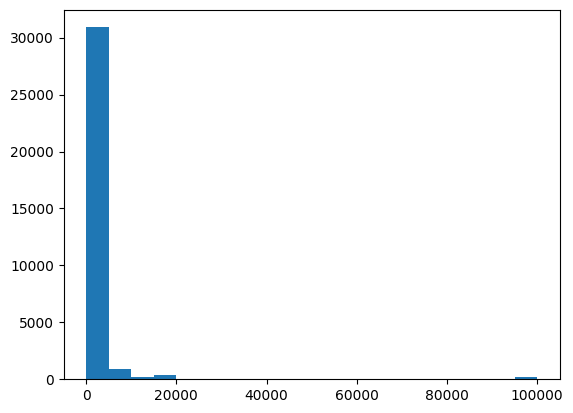

In [100]:
plt.hist(df['capital-gain'],bins=20)

In [101]:
df['capital-gain'].skew()

np.float64(11.953847687699804)

In [102]:
df.isna().sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     583
income               0
dtype: int64

In [103]:
df.duplicated().sum()

np.int64(24)

In [104]:
df.drop_duplicates(inplace=True)

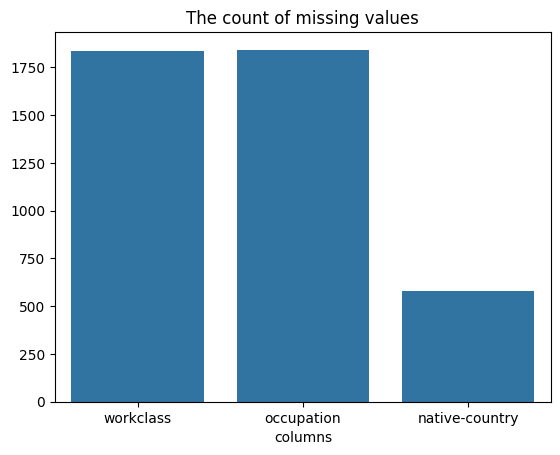

In [105]:
miss_value=df.isna().sum()
miss_value=miss_value[miss_value>0]
sns.barplot(x=miss_value.index,y=miss_value.values)
plt.title('The count of missing values')
plt.xlabel('columns')
plt.show()


Text(0.5, 1.0, 'Income distribution')

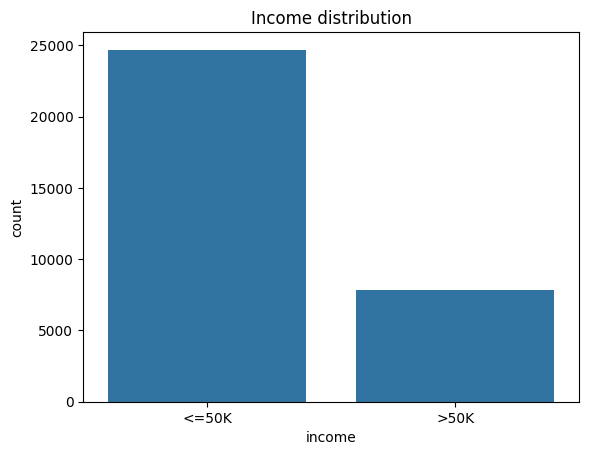

In [106]:
sns.countplot(data=df,x='income')
plt.title('Income distribution')

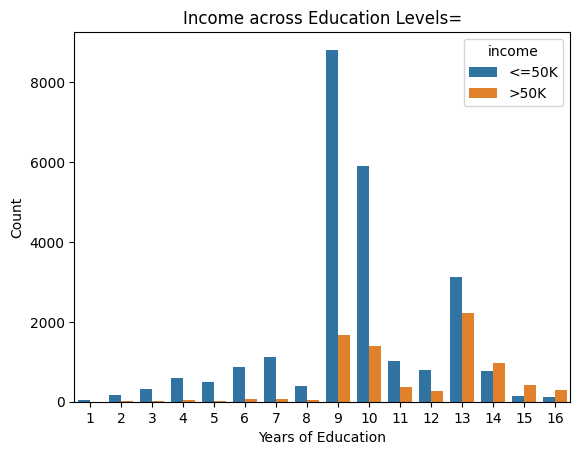

In [107]:
sns.countplot(data=df,x='education-num',hue='income')
plt.title('Income across Education Levels=')
plt.xlabel('Years of Education')
plt.ylabel('Count')
plt.show()

<Axes: xlabel='age', ylabel='count'>

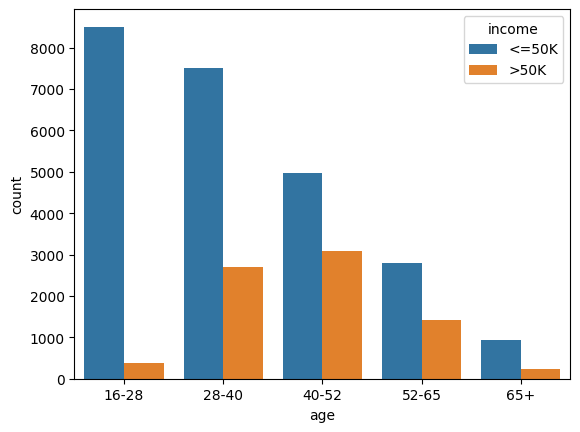

In [108]:
bins=[16,28,40,52,65,100]
labels=['16-28','28-40','40-52','52-65','65+']
age_groups=pd.cut(df['age'],bins=bins,labels=labels)
sns.countplot(data=df,x=age_groups,hue='income')

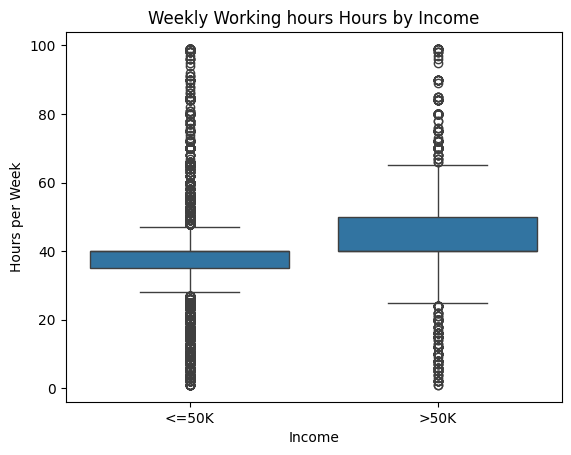

In [109]:
sns.boxplot(data=df,x='income',y='hours-per-week')
plt.title('Weekly Working hours Hours by Income')
plt.xlabel('Income')
plt.ylabel('Hours per Week')
plt.show()

In [110]:
df['occupation'].value_counts().index

Index(['Prof-specialty', 'Craft-repair', 'Exec-managerial', 'Adm-clerical',
       'Sales', 'Other-service', 'Machine-op-inspct', 'Transport-moving',
       'Handlers-cleaners', 'Farming-fishing', 'Tech-support',
       'Protective-serv', 'Priv-house-serv', 'Armed-Forces'],
      dtype='object', name='occupation')

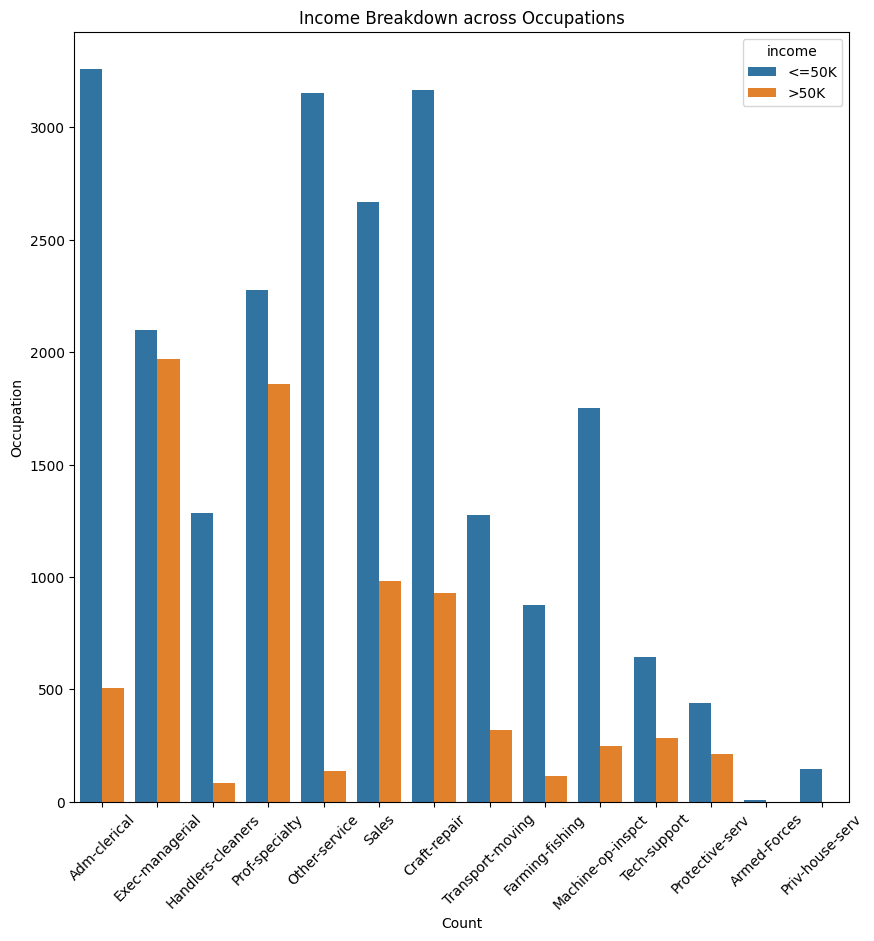

In [111]:
plt.figure(figsize=(10,10))
sns.countplot(data=df,x='occupation',hue='income')
plt.title('Income Breakdown across Occupations')
plt.xlabel('Count')
plt.ylabel('Occupation')
plt.xticks(rotation=45)
plt.show()

In [112]:
corelation=df[df.select_dtypes(include='number').columns].corr()

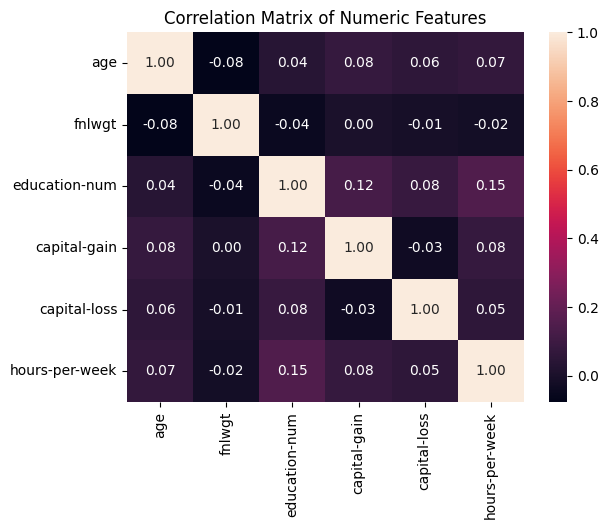

In [113]:
sns.heatmap(corelation,annot=True,fmt='.2f')
plt.title('Correlation Matrix of Numeric Features')
plt.show()

In [114]:
x=df.drop(columns=['income'])
y=df['income']

In [115]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=42,stratify=y)

In [116]:
y_train = y_train.apply(lambda val: 1 if '>50K' in str(val) else 0)
y_test = y_test.apply(lambda val: 1 if '>50K' in str(val) else 0)

In [117]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [118]:
numerical_feature=x_train.select_dtypes(include='number').columns
numerical_feature

Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

In [119]:
categorical_feature=x_train.select_dtypes(include='object').columns
categorical_feature

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')

In [120]:
numerical_transform=Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='median')),
    ('stander_scaler',StandardScaler())
])
categorical_transform=Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('one_hot',OneHotEncoder(sparse_output=False,handle_unknown='ignore'))
])

In [121]:
preprosseing=ColumnTransformer(
    transformers=[
        ('numbers',numerical_transform,numerical_feature),
        ('categoricals',categorical_transform,categorical_feature)
    ]
)

In [122]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate,StratifiedKFold

In [123]:
models={
    'LogisticRegression':Pipeline(steps=[
        ('preprossecor',preprosseing),
        ('classification',LogisticRegression(max_iter=1000,random_state=42))
    ]),
    'KNN':Pipeline(steps=[
        ('preprossecor',preprosseing),
        ('classification',KNeighborsClassifier(n_neighbors=5))
    ]),
    'Random_forest':Pipeline(steps=[
        ('preprossecor',preprosseing),
        ('classification',RandomForestClassifier(n_estimators=100,random_state=42))
    ])
}


In [124]:
score=['precision','f1','roc_auc','recall']
cv_est=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)


In [125]:
result=[]
for model_name,model in models.items():
    cv_result=cross_validate(model,x_train,y_train,scoring=score,cv=cv_est,n_jobs=-1)
    result.append({
        'Model':model_name,
        'Precision':cv_result['test_precision'].mean(),
        'Recall':cv_result['test_recall'].mean(),
        'F1':cv_result['test_f1'].mean(),
        'Roc_Auc':cv_result['test_roc_auc'].mean()
    })
result_df=pd.DataFrame(result)
result_df

,Model,Precision,Recall,F1,Roc_Auc
0,LogisticRegression,0.730907,0.589059,0.652335,0.904238
1,KNN,0.666986,0.599743,0.631443,0.857398
2,Random_forest,0.728672,0.618879,0.669257,0.900585


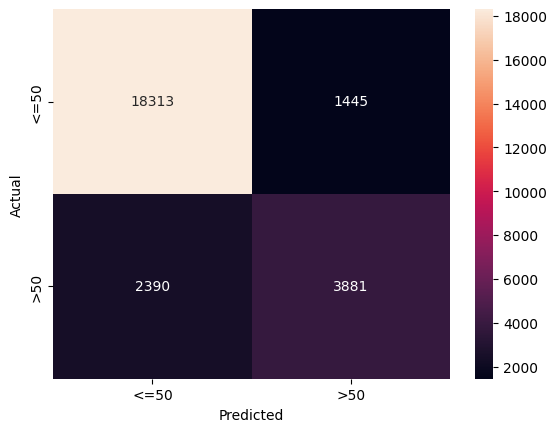

In [126]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix,classification_report,roc_auc_score
y_pred = cross_val_predict(models['Random_forest'], x_train, y_train, cv=cv_est, n_jobs=-1)
cm=confusion_matrix(y_train,y_pred)
sns.heatmap(cm,annot=True,xticklabels=['<=50','>50'],yticklabels=['<=50','>50'],fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [127]:
l1 = Pipeline(steps=[
    ('preprocessor', preprosseing),
    ('classifier', LogisticRegression(penalty='l1', solver='liblinear', random_state=42))
])

In [128]:
cv_l1=cross_validate(l1,x_train,y_train,scoring=score,cv=cv_est,n_jobs=-1)
print("F1 before L1:", result_df.loc[result_df['Model'] == 'LogisticRegression', 'F1'].values[0])
print("F1 after L1:", cv_l1['test_f1'].mean())

F1 before L1: 0.6523352739364351
F1 after L1: 0.6530453212822745


In [129]:
from sklearn.model_selection import GridSearchCV

In [130]:
param_grid={
    'classification__n_estimators':[100,200,400],
    'classification__max_depth':[10,20,None]
}

In [131]:
GSV=GridSearchCV(models['Random_forest'],param_grid=param_grid,cv=cv_est,n_jobs=-1,scoring='f1')
GSV.fit(x_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classification__max_depth': [10, 20, ...], 'classification__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose

In [132]:
#model1=models['Random_forest']
model1=GSV.best_estimator_
model1.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprossecor', ...), ('classification', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['age','workclass','fnlwgt',...,'capital-loss','hours-per-week', 'native-country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numbers', ...), ('categoricals', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying 

In [133]:
y_pred_test=model1.predict(x_test)

In [134]:
y_pred_prob=model1.predict_proba(x_test)[:,1]

In [135]:
print(classification_report(y_test,y_pred_test,target_names=['<=50','>50']))

              precision    recall  f1-score   support

        <=50       0.89      0.95      0.92      4940
         >50       0.80      0.62      0.70      1568

    accuracy                           0.87      6508
   macro avg       0.84      0.79      0.81      6508
weighted avg       0.87      0.87      0.87      6508



In [136]:
print(f'Roc_auc_score: {roc_auc_score(y_test,y_pred_prob)}')

Roc_auc_score: 0.9222346732215153


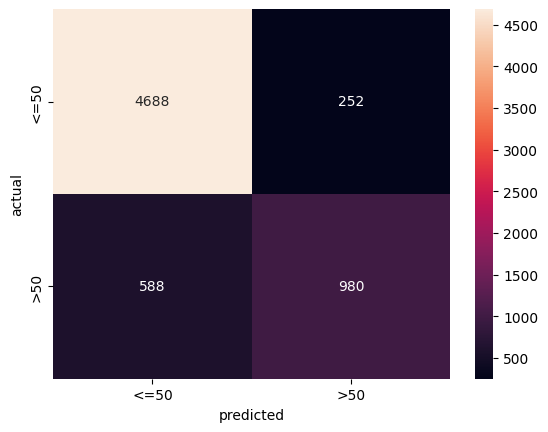

In [137]:
cm1=confusion_matrix(y_test,y_pred_test)
sns.heatmap(cm1,annot=True,fmt='d',xticklabels=['<=50','>50'],yticklabels=['<=50','>50'])
plt.xlabel('predicted')
plt.ylabel('actual')
plt.show()

In [138]:
error_analysis=x_test.copy()
error_analysis['True_income']=y_test
error_analysis['predicted_income']=y_pred_test
FP=(error_analysis[(error_analysis['True_income']==0)&(error_analysis['predicted_income']==1)])
FP.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,True_income,predicted_income
12518,60,Private,88055,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,3781,0,16,United-States,0,1
1582,29,Private,200511,Bachelors,13,Married-civ-spouse,Sales,Husband,White,Male,0,0,50,United-States,0,1
25212,52,Federal-gov,207841,Some-college,10,Married-civ-spouse,Adm-clerical,Husband,White,Male,0,0,40,United-States,0,1
31823,58,Local-gov,294313,Some-college,10,Married-civ-spouse,Adm-clerical,Wife,Black,Female,0,0,55,United-States,0,1
116,56,Self-emp-inc,303090,Some-college,10,Married-civ-spouse,Sales,Husband,White,Male,0,0,50,United-States,0,1


In [139]:
FN=((error_analysis[(error_analysis['True_income']==1)&(error_analysis['predicted_income']==0)]))
FN.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,True_income,predicted_income
7275,42,State-gov,104663,Doctorate,16,Never-married,Exec-managerial,Not-in-family,White,Female,0,0,40,Italy,1,0
455,40,Private,72887,Assoc-voc,11,Married-civ-spouse,Machine-op-inspct,Husband,Asian-Pac-Islander,Male,0,0,40,United-States,1,0
13914,66,Private,205724,Some-college,10,Married-civ-spouse,Sales,Husband,White,Male,0,0,24,United-States,1,0
29192,52,Private,165681,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,1,0
24471,51,Federal-gov,174102,HS-grad,9,Married-civ-spouse,Adm-clerical,Husband,White,Male,0,0,40,United-States,1,0
